# What does the database actually read for `SELECT * FROM users WHERE email = ?`

The companion notebook to `notes.pdf`. You build a `users` table in SQLite, then open the database **file**
and read its pages yourself: the page size in the file's header, the table's tree of pages, the scan, the
index's tree, the exact pages one lookup reads, and the questions the index's sort order can and can't answer.

Everything here is the Python standard library (`sqlite3`, plus a page reader short enough to read in one
sitting, which follows SQLite's [file format spec](https://www.sqlite.org/fileformat2.html)). It runs in
seconds. Nothing is timed: it prints what is in the file, never how long something took. Set
`FULL = True` for the notes' table of 1,000,000 rows: the same seed, the same rows, and with SQLite
3.45.3 the same page numbers as the notes, to the page.

The numbers in the text ("our run") are from that full table. The outputs below come from the quick default,
a table ten times smaller: other ids and page numbers, the same shape.

The users are made up. Each email pairs a common first name with a common last name, drawn at random, at one
of the big mail providers, so the addresses look real without being anyone's.

In [1]:
FULL = False                      # True: the notes' table (about 20 s for the whole notebook, 90 MB on disk)
N = 1_000_000 if FULL else 100_000

import os
import random
import shutil
import sqlite3
import tempfile

try:
    import matplotlib.pyplot as plt
except ImportError:               # the one chart is optional; its numbers are printed too
    plt = None

SEED, TARGET = 2026, "maria.lopez@gmail.com"
PROBE = ("daniel.kim@outlook.com", "Seoul", 31)   # one new user, written and deleted again (section 8)
SCHEMA = "CREATE TABLE users (id INTEGER PRIMARY KEY, email TEXT COLLATE NOCASE, city TEXT, age INTEGER)"
LINE = "SELECT * FROM users WHERE email = ?"
DOMAINS = {"gmail.com": 50, "yahoo.com": 12, "outlook.com": 12, "icloud.com": 10, "hotmail.com": 10, "proton.me": 6}
CITIES = ["Almaty", "Berlin", "Cairo", "Lima", "Oslo", "Paris", "Seoul", "Tokyo"]
FIRST = """emma olivia ava sophia mia isabella amelia harper ella grace chloe lily zoe hannah sarah anna laura julia
maria sofia lucia elena carmen ana paula camila valentina gabriela daniela aigerim aliya dana madina zarina dinara
asel kamila amina fatima leila yasmin nora ingrid freya astrid mei yuki hana sakura minji seoyeon priya ananya divya
aisha zainab james john michael david daniel matthew andrew ryan ethan noah liam lucas mason logan jacob william
thomas oliver jack henry samuel benjamin alexander max leon felix jonas lukas paul marco luca matteo diego carlos
javier pablo miguel mateo santiago arman timur daniyar aidar yerlan askar ruslan omar ali hassan karim yusuf ivan
dmitri alexei sergei kenji haruto takumi minho jisung wei jun raj arjun rohan vikram kwame kofi tunde emeka""".split()
LAST = """smith johnson williams brown jones miller davis wilson anderson taylor thomas moore martin jackson white harris
clark lewis walker hall young king wright scott green baker adams nelson hill campbell garcia rodriguez martinez
hernandez lopez gonzalez perez sanchez ramirez torres flores rivera gomez diaz morales ortiz castro silva santos
oliveira costa pereira ferreira rossi russo ferrari esposito bianchi romano colombo mueller schmidt schneider fischer
weber meyer wagner becker hoffmann novak kowalski nowak ivanov petrov smirnov popov volkov sokolov kim lee park choi
jung kang cho yoon tanaka suzuki sato takahashi watanabe ito nakamura wang li zhang liu chen yang huang zhao nguyen
tran pham patel sharma singh kumar gupta khan ahmed hassan ibrahim mensah okafor adeyemi nurlanov seitkali abenov
akhmetov omarov bekov iskakov suleimenov kassymov tulegenov ospanov""".split()


def email_maker(rng, reserved):
    """Real-looking, unique emails: maria.lopez@gmail.com, jkim@yahoo.com, sara_lee92@icloud.com, ..."""
    used, domains, weights = set(reserved), list(DOMAINS), list(DOMAINS.values())

    def make():
        first, last = rng.choice(FIRST), rng.choice(LAST)
        style = rng.random()
        if style < 0.40:
            local = f"{first}.{last}"
        elif style < 0.55:
            local = f"{first}{last}"
        elif style < 0.65:
            local = f"{first}_{last}"
        elif style < 0.75:
            local = f"{first[0]}{last}"
        elif style < 0.90:
            local = f"{first}.{last}{rng.randint(1, 99)}"
        else:
            local = f"{first}{rng.randint(1970, 2007)}"
        domain = rng.choices(domains, weights)[0]
        email = f"{local}@{domain}"
        while email in used:                      # taken: add digits, as a real sign-up form makes you do
            email = f"{local}{rng.randint(1, 999)}@{domain}"
        used.add(email)
        return email
    return make


def build(path, rows):
    """users(id, email, city, age): exactly one row is maria.lopez@gmail.com. No index yet."""
    con = sqlite3.connect(path)
    con.execute(SCHEMA)
    rng = random.Random(SEED)
    target_at = rng.randrange(rows)
    make_email = email_maker(rng, {TARGET, PROBE[0]})

    def gen():
        for i in range(rows):
            email = TARGET if i == target_at else make_email()
            yield email, rng.choice(CITIES), rng.randint(18, 70)

    con.executemany("INSERT INTO users (email, city, age) VALUES (?, ?, ?)", gen())
    con.commit()
    return con


def plan(sql, args=()):
    """SQLite's own answer to 'how will you run this?', on one line."""
    return " / ".join(r[-1] for r in con.execute("EXPLAIN QUERY PLAN " + sql, args))


WORK = tempfile.mkdtemp(prefix="db-index-")
DB = os.path.join(WORK, "users.db")
con = build(DB, N)
print(f"SQLite {sqlite3.sqlite_version} · {N:,} rows · {os.path.getsize(DB):,} bytes in {DB}")
print(con.execute("SELECT * FROM users LIMIT 3").fetchall())

SQLite 3.45.3 · 100,000 rows · 3,989,504 bytes in /var/folders/wm/7lpcd5bn469gngbhdy6r71vm0000gn/T/db-index-2r0uduib/users.db
[(1, 'yasmin1976@hotmail.com', 'Seoul', 68), (2, 'oliver.kowalski99@gmail.com', 'Tokyo', 33), (3, 'emma.kim@gmail.com', 'Berlin', 46)]


## 1. The line you write

You type your email to log in, and the app asks the database for your row. Our run on the full table:
`maria.lopez@gmail.com` is row 124,907, in Lima, age 36. On the small table
it has another id: the rows are different, the picture isn't.

In [2]:
print(con.execute(LINE, (TARGET,)).fetchall())

[(15614, 'maria.lopez@gmail.com', 'Tokyo', 26)]


## 2. The file is pages

A SQLite database is one file, cut into **pages** that all have the same size. The first 100 bytes
of the file are its header: bytes `16-17` say how big a page is, bytes `28-31` how many pages there are. The
database reads and writes whole pages, so pages are the unit to count.

A table is stored as a **B-tree** of those pages: **leaf** pages at the bottom hold the rows, in id order, and
**signpost** pages above them (SQLite calls them interior pages) say which leaf holds which ids. Our run:
1 root page at the top, 25 signpost pages,
10,009 leaves of about 100 rows each.

In [3]:
with open(DB, "rb") as f:
    head = f.read(100)
SIZE = int.from_bytes(head[16:18], "big")
print(head[:16], "· page size", SIZE, "· pages in the file", int.from_bytes(head[28:32], "big"))
print("PRAGMA page_size →", con.execute("PRAGMA page_size").fetchone()[0])
ROOT = dict(con.execute("SELECT name, rootpage FROM sqlite_master WHERE rootpage > 0"))
print("root pages:", ROOT)

b'SQLite format 3\x00' · page size 4096 · pages in the file 974
PRAGMA page_size → 4096
root pages: {'users': 2}


SQLite can describe its own pages through the `dbstat` table (most builds have it). Each row is one page:
which tree it belongs to, where it sits (`path`), its type and how many cells (rows or keys) it holds.

In [4]:
try:
    for row in con.execute("SELECT pagetype, count(*), sum(ncell) FROM dbstat WHERE name = 'users' "
                           "GROUP BY pagetype"):
        print(row)
    print(con.execute("SELECT pageno, path, pagetype, ncell FROM dbstat WHERE name = 'users' LIMIT 4").fetchall())
except sqlite3.OperationalError as e:
    print("this SQLite build has no dbstat:", e, "· the page reader below needs nothing from it")

('internal', 4, 968)
('leaf', 969, 100000)
[(2, '/', 'internal', 2), (475, '/000/', 'internal', 358), (3, '/000/000/', 'leaf', 111), (4, '/000/001/', 'leaf', 107)]


Now without SQLite's help. Each tree page starts with a small header: byte 0 is the page type (`0x0D` table
leaf, `0x05` table interior, `0x0A` index leaf, `0x02` index interior), bytes `3-4` the number of cells, and on
interior pages bytes `8-11` the right-most child. After the header comes a list of 2-byte offsets, one per
cell, and the cells themselves are packed from the end of the page backwards. A cell is a little record:
varints (SQLite's variable-length integers) for its size and the rowid, a header of column types, then the
values.

This is the whole reader. It follows the [file format spec](https://www.sqlite.org/fileformat2.html) (its
B-tree pages and record format sections); there is no SQLite call in it.

In [5]:
KIND = {2: "index interior", 5: "table interior", 10: "index leaf", 13: "table leaf"}


def varint(b, i):
    v = 0
    for k in range(8):
        v = (v << 7) | (b[i + k] & 0x7F)
        if b[i + k] < 0x80:
            return v, i + k + 1
    return (v << 8) | b[i + 8], i + 9


def record(b, i):
    """Column values of one record. Rows here are short, so no cell spills onto overflow pages."""
    hlen, j = varint(b, i)
    types, out, p = [], [], i + hlen
    while j < i + hlen:
        t, j = varint(b, j)
        types.append(t)
    for t in types:
        if t == 0:
            out.append(None)                                  # NULL, and the id column (it is the rowid)
        elif t in (8, 9):
            out.append(t - 8)
        elif t <= 6:
            n = (0, 1, 2, 3, 4, 6, 8)[t]
            out.append(int.from_bytes(b[p:p + n], "big", signed=True))
            p += n
        else:                                                 # odd ≥ 13: text of (t - 13) / 2 bytes
            n = (t - 13) // 2
            out.append(b[p:p + n].decode())
            p += n
    return out


READS = []                                                    # every page we read, in order
FILE = open(DB, "rb")                                         # sees every later write: same file


def raw(pgno):
    FILE.seek((pgno - 1) * SIZE)
    return FILE.read(SIZE)


def header(pgno):
    """(page type, number of cells) from the page header alone."""
    b = raw(pgno)
    h = 100 if pgno == 1 else 0
    return KIND[b[h]], int.from_bytes(b[h + 3:h + 5], "big")


def page(pgno):
    """One page, decoded: its type, its cells, its right-most child."""
    READS.append(pgno)
    b = raw(pgno)
    h = 100 if pgno == 1 else 0
    kind, ncell = KIND[b[h]], int.from_bytes(b[h + 3:h + 5], "big")
    interior = b[h] in (2, 5)
    ptrs = h + (12 if interior else 8)
    cells = []
    for k in range(ncell):
        off = int.from_bytes(b[ptrs + 2 * k:ptrs + 2 * k + 2], "big")
        if b[h] == 5:                                         # table interior: child page, largest rowid on its left
            cells.append((int.from_bytes(b[off:off + 4], "big"), varint(b, off + 4)[0]))
        elif b[h] == 13:                                      # table leaf: size, rowid, record
            _, j = varint(b, off)
            rowid, j = varint(b, j)
            cells.append((rowid, [rowid] + record(b, j)[1:]))
        elif b[h] == 2:                                       # index interior: child page, size, record
            _, j = varint(b, off + 4)
            cells.append((int.from_bytes(b[off:off + 4], "big"), record(b, j)))
        else:                                                 # index leaf: size, record
            _, j = varint(b, off)
            cells.append((None, record(b, j)))
    right = int.from_bytes(b[h + 8:h + 12], "big") if interior else None
    return {"pgno": pgno, "kind": kind, "interior": interior, "cells": cells, "right": right, "raw": b}


def levels(root):
    """Page numbers per level, root first (only the signpost pages are decoded)."""
    out, level = [], [root]
    while True:
        out.append(level)
        if "leaf" in header(level[0])[0]:                     # every leaf is at the same depth
            return out
        pages = [page(p) for p in level]
        level = [c for p in pages for c in [c for c, _ in p["cells"]] + [p["right"]]]


def leaves(root):
    """Every leaf of a tree, left to right: the order a scan reads them."""
    p = page(root)
    if not p["interior"]:
        yield p
        return
    for child in [c for c, _ in p["cells"]] + [p["right"]]:
        yield from leaves(child)


first = next(leaves(ROOT["users"]))
print(f"page {first['pgno']}: header bytes {first['raw'][:8].hex(' ')} → {first['kind']}, {len(first['cells'])} rows,"
      f" ids {first['cells'][0][0]} … {first['cells'][-1][0]}")
for rowid, row in first["cells"][:3]:
    print("  ", row)
shape = [len(lv) for lv in levels(ROOT["users"])]
print("the table's tree, pages per level:", shape)

page 3: header bytes 0d 00 00 00 6f 00 fd 00 → table leaf, 111 rows, ids 1 … 111
   [1, 'yasmin1976@hotmail.com', 'Seoul', 68]
   [2, 'oliver.kowalski99@gmail.com', 'Tokyo', 33]
   [3, 'emma.kim@gmail.com', 'Berlin', 46]
the table's tree, pages per level: [1, 3, 969]


Our run: page 3 is the first leaf, ids 1 to
111, starting with `yasmin1976@hotmail.com`; the tree has 3 levels.
Page 1 is the file header and the schema; page 2 is the table's root. Nothing in this
layout is ordered by email.

## 3. No index: SQLite reads every page

Ask for the plan first: `SCAN users` means read the table from its first leaf to its last. Then do what the
scan does: walk the leaves left to right and look at every row. Our run met `maria.lopez@gmail.com` on leaf
1,214 of 10,009 (page 1,219), and kept reading, because
`email` isn't unique and another row could match on any later page: 10,035 pages in all.

The email column was declared `COLLATE NOCASE`: it ignores upper and lower case (A-Z), so the comparison below
folds case the same way.

In [6]:
UPPER = {c: c + 32 for c in range(ord("A"), ord("Z") + 1)}


def nocase(s):
    """What SQLite's NOCASE collation compares: A-Z folded to a-z, nothing else."""
    return s.translate(UPPER)


print(LINE, "→", plan(LINE, (TARGET,)))
READS.clear()
n_leaves, hits = 0, []
for n_leaves, leaf in enumerate(leaves(ROOT["users"]), 1):
    hits += [(n_leaves, leaf["pgno"], row) for _, row in leaf["cells"] if nocase(row[1]) == TARGET]
print(f"found {hits} · leaves read: {n_leaves:,} · pages read in all (signposts too): {len(READS):,}")

SELECT * FROM users WHERE email = ? → SCAN users


found [(147, 149, [15614, 'maria.lopez@gmail.com', 'Tokyo', 26])] · leaves read: 969 · pages read in all (signposts too): 973


## 4. `CREATE INDEX`: a second tree of sorted `(email, id)` pairs

`CREATE INDEX` reads every row, copies out the email and the row's id, sorts the pairs by email, and writes
them into pages of their own: a second B-tree in the same file. Our run: 8,041 pages, the root on
page 10,037 (right after the table's last page), 7,967 leaves of about
125 entries each.

The next cell also writes one new user, daniel.kim@outlook.com, and deletes the row again, as the notes' run did at
this point: section 8 looks at what that write changed. (It also keeps the page numbers equal to the notes'.)

In [7]:
def one_write(row=PROBE):
    """INSERT one row and commit, compare the file page by page, DELETE it again. Returns {page: tree}."""
    with open(DB, "rb") as f:
        before = f.read()
    con.execute("INSERT INTO users (email, city, age) VALUES (?, ?, ?)", row)
    con.commit()
    with open(DB, "rb") as f:
        after = f.read()
    changed = [i + 1 for i in range(len(after) // SIZE)
               if before[i * SIZE:(i + 1) * SIZE] != after[i * SIZE:(i + 1) * SIZE]]
    owner = {p: name for name, root in ROOT.items() for lv in levels(root) for p in lv}
    con.execute("DELETE FROM users WHERE email = ?", (row[0],))
    con.commit()
    return {p: ("file header" if p == 1 else owner.get(p, "?")) for p in changed}


WRITES = {"no index": one_write()}                            # what one write changes with no index (section 8)
con.execute("CREATE INDEX idx_users_email ON users(email)")
con.commit()
ROOT = dict(con.execute("SELECT name, rootpage FROM sqlite_master WHERE rootpage > 0"))
WRITES["+ index on email"] = one_write()
print(ROOT)
ix_levels = levels(ROOT["idx_users_email"])
print("the index's tree, pages per level:", [len(lv) for lv in ix_levels])
ix_first = page(ix_levels[-1][0])
print(f"its first leaf, page {ix_first['pgno']} ({ix_first['kind']}):")
for _, entry in ix_first["cells"][:4]:
    print("  ", entry)
per_leaf = sum(header(p)[1] for p in ix_levels[-1]) / len(ix_levels[-1])
t_leaves = levels(ROOT["users"])[-1]
print(f"entries per index leaf: {per_leaf:.0f} · rows per table leaf: "
      f"{sum(header(p)[1] for p in t_leaves) / len(t_leaves):.0f}")

{'users': 2, 'idx_users_email': 975}
the index's tree, pages per level: [1, 8, 762]
its first leaf, page 976 (index leaf):
   ['aabenov291@gmail.com', 19566]
   ['aabenov598@hotmail.com', 91915]
   ['aabenov849@outlook.com', 70088]
   ['aabenov904@gmail.com', 22687]
entries per index leaf: 130 · rows per table leaf: 103


Each entry is a record of two values: the email and the row's id. No city, no age. An entry is shorter than a
row, so a leaf holds more of them (125 against 100 rows).

## 5. Signposts: from the root to the leaf

Above the leaves sit signpost pages. Each holds a row of keys in order, and between two keys a pointer to the
page with everything in between. A lookup reads the root, finds the first key that is not smaller than the
one it wants, follows the pointer just before it, and repeats until it reaches a leaf.

Our run: the root (page 10,037) has 72 keys and
73 children; `maria.lopez@gmail.com` falls between `marco.popov907@hotmail.com` and
`mason.oliveira114@gmail.com`, which sends it to page 14,971; there it falls between
`maria.lee@gmail.com` and `maria.martin135@icloud.com`, which sends it to leaf 15,020, where
it is entry 122 of 130, with id 124,907.

In [8]:
def descend(root, key):
    """The pages one lookup reads, root to leaf. key: an email (the index, compared ignoring case) or an id."""
    path, pgno = [], root
    is_index = isinstance(key, str)
    if is_index:
        key = nocase(key)
    while True:
        p = page(pgno)
        if is_index:
            keys = [nocase(c[1][0]) for c in p["cells"]]
        else:
            keys = [c[1] if p["interior"] else c[0] for c in p["cells"]]
        if not p["interior"]:
            path.append((p, keys.index(key) if key in keys else None))
            return path
        b = next((i for i, k in enumerate(keys) if key <= k), len(keys))
        path.append((p, b))
        if is_index and b < len(keys) and keys[b] == key:
            return path                                       # index B-trees keep entries on signpost pages too
        pgno = p["cells"][b][0] if b < len(keys) else p["right"]


READS.clear()
for p, b in descend(ROOT["idx_users_email"], TARGET):
    keys = [c[1][0] for c in p["cells"]]
    if p["interior"]:
        lo = keys[b - 1] if b else "(start)"
        hi = keys[b] if b < len(keys) else "(end)"
        print(f"page {p['pgno']:>6,} {p['kind']:<15} {len(keys):>3} keys: {lo} < {TARGET} ≤ {hi} → child {b + 1}")
    else:
        print(f"page {p['pgno']:>6,} {p['kind']:<15} {len(keys):>3} entries: entry {b + 1} = {p['cells'][b][1]}")
        ROWID = p["cells"][b][1][1]

page    975 index interior    7 keys: madina.wang@gmail.com < maria.lopez@gmail.com ≤ paul.costa@proton.me → child 6
page  1,443 index interior  115 keys: maria.green@hotmail.com < maria.lopez@gmail.com ≤ maria.oliveira42@proton.me → child 10
page  1,452 index leaf      128 entries: entry 86 = ['maria.lopez@gmail.com', 15614]


## 6. The id leads down the table's own tree

`SELECT *` wants the whole row, and the index holds only the email and the id. So SQLite takes the id down the
table's tree, whose signposts are ids: our run went through pages 2,
1,386 and 1,219, where the row is number 50 of
100. That makes 6 pages in all. The plan names the index:
`SEARCH users USING INDEX idx_users_email (email=?)`.

In [9]:
for p, b in descend(ROOT["users"], ROWID):
    if p["interior"]:
        n = len(p["cells"])
        print(f"page {p['pgno']:>6,} {p['kind']:<15} {n:>3} key{'s' * (n != 1)} → child {b + 1}")
    else:
        print(f"page {p['pgno']:>6,} {p['kind']:<15} {len(p['cells']):>3} rows: row {b + 1} = {p['cells'][b][1]}")
print(f"pages read for one SELECT *: {len(READS)} → {READS}")
print(LINE, "→", plan(LINE, (TARGET,)))
print("SELECT id … →", plan("SELECT id FROM users WHERE email = ?", (TARGET,)))

page      2 table interior    2 keys → child 1
page    475 table interior  358 keys → child 147
page    149 table leaf      107 rows: row 26 = [15614, 'maria.lopez@gmail.com', 'Tokyo', 26]
pages read for one SELECT *: 6 → [975, 1443, 1452, 2, 475, 149]
SELECT * FROM users WHERE email = ? → SEARCH users USING INDEX idx_users_email (email=?)
SELECT id … → SEARCH users USING COVERING INDEX idx_users_email (email=?)


`SELECT id` stops after the index's pages: the id is already in the entry (`COVERING INDEX`).

## 7. So that's why: questions the sort order can and can't answer

The index is sorted by email from the first letter. **A leading wildcard** (`'%@yahoo.com'`, every
email that ends in `@yahoo.com`) asks about the end of the email, so the matches start with any letter and sit
everywhere: our run found 120,579 of them, on 7,967 of the 7,967 leaf
pages, and SQLite answered `SCAN users`. **A prefix** (`'maria.lo%'`, every email that starts
with `maria.lo`) is one stretch of the sorted order: all 35 matches sat on
1 leaf page, and the plan was `SEARCH users USING INDEX idx_users_email (email>? AND email<?)`. `LIKE` ignores upper and lower case,
and so does this index (`COLLATE NOCASE`), which is why `LIKE` can use it at all.

SELECT * FROM users WHERE email LIKE '%@yahoo.com' → SCAN users · 12,227 matches
SELECT * FROM users WHERE email LIKE 'maria.lo%' → SEARCH users USING INDEX idx_users_email (email>? AND email<?) · 5 matches


'%@yahoo.com': matches on 762 of 762 leaves · 'maria.lo%': on leaves [473]


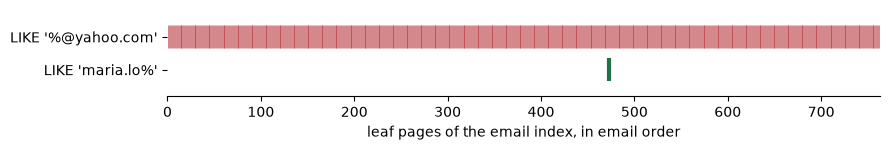

In [10]:
def leaves_with(root, test):
    """Leaf numbers (left to right) that hold at least one entry passing `test`, and how many leaves there are."""
    hit, n = [], 0
    for n, leaf in enumerate(leaves(root), 1):
        if any(test(e) for _, e in leaf["cells"]):
            hit.append(n)
    return hit, n


for arg in ["%@yahoo.com", "maria.lo%"]:
    sql = "SELECT * FROM users WHERE email LIKE ?"
    count = con.execute("SELECT count(*) FROM users WHERE email LIKE ?", (arg,)).fetchone()[0]
    print(f"{sql.replace('?', repr(arg)):<48} → {plan(sql, (arg,))} · {count:,} matches")
wild, n_ix = leaves_with(ROOT["idx_users_email"], lambda e: nocase(e[0]).endswith("@yahoo.com"))
pre, _ = leaves_with(ROOT["idx_users_email"], lambda e: nocase(e[0]).startswith("maria.lo"))
print(f"'%@yahoo.com': matches on {len(wild):,} of {n_ix:,} leaves · 'maria.lo%': on leaves {pre}")

if plt:
    fig, ax = plt.subplots(figsize=(9, 1.6))
    ax.eventplot([wild, pre], colors=["#B42A30", "#1E7346"], lineoffsets=[1, 0], linelengths=0.7,
                 linewidths=[0.4, 3])
    ax.set_yticks([1, 0], ["LIKE '%@yahoo.com'", "LIKE 'maria.lo%'"])
    ax.set_xlim(0, n_ix + 1)
    ax.set_xlabel("leaf pages of the email index, in email order")
    ax.spines[["top", "right", "left"]].set_visible(False)
    plt.tight_layout()
    plt.show()

**Two columns work left to right.** An index on `(city, age)` sorts by city first and by age only inside each
city, like a phone book sorted by last name, then first name. So `city`, or `city` and `age`, is one stretch
of the index: a search. `age` alone is spread across every city: a scan. Our run:
`SEARCH users USING INDEX idx_users_city_age (city=?)`, `SEARCH users USING INDEX idx_users_city_age (city=? AND age=?)`, `SCAN users`.

In [11]:
con.execute("CREATE INDEX idx_users_city_age ON users(city, age)")
con.commit()
ROOT = dict(con.execute("SELECT name, rootpage FROM sqlite_master WHERE rootpage > 0"))
WRITES["+ index on (city, age)"] = one_write()
city, age = con.execute(LINE, (TARGET,)).fetchone()[2:]
for where, args in [("city = ?", (city,)), ("city = ? AND age = ?", (city, age)), ("age = ?", (age,))]:
    print(f"WHERE {where:<22} {str(args):<14} → {plan('SELECT * FROM users WHERE ' + where, args)}")
c_levels = levels(ROOT["idx_users_city_age"])
print("first entries (city, age, id):", [e for _, e in page(c_levels[-1][0])["cells"][:3]])
same_age, n_c = leaves_with(ROOT["idx_users_city_age"], lambda e: e[1] == age)
stretches = sum(1 for i, x in enumerate(same_age) if i == 0 or x != same_age[i - 1] + 1)
print(f"age = {age} sits on {len(same_age)} of {n_c:,} leaves, in {stretches} separate stretches (one per city)")

WHERE city = ?               ('Tokyo',)     → SEARCH users USING INDEX idx_users_city_age (city=?)
WHERE city = ? AND age = ?   ('Tokyo', 26)  → SEARCH users USING INDEX idx_users_city_age (city=? AND age=?)
WHERE age = ?                (26,)          → SCAN users
first entries (city, age, id): [['Almaty', 18, 577], ['Almaty', 18, 716], ['Almaty', 18, 1609]]


age = 26 sits on 16 of 384 leaves, in 8 separate stretches (one per city)


## 8. Every write updates every index

The three test writes from above, one new user each time. With no index, our run changed
2 pages: the file header (its change counter) and the table's last leaf, where the
new largest id goes. With the email index, 9 pages of the index changed as
well: `CREATE INDEX` packs its leaves full, so the leaf where the new email belongs had to split, and the change
climbed up to the root. With two indexes, every tree changed: 3 B-trees for one
row. (On the small table the pages differ, and so may the size of the split.)

In [12]:
for stage, pages in WRITES.items():
    trees = sorted(set(pages.values()) - {"file header"})
    print(f"{stage:<24} {len(pages):>2} pages changed in {trees}: {sorted(pages)}")

no index                  2 pages changed in ['users']: [1, 974]
+ index on email         11 pages changed in ['idx_users_email', 'users']: [1, 974, 975, 1092, 1093, 1129, 1130, 1131, 1210, 1744, 1745]
+ index on (city, age)    8 pages changed in ['idx_users_city_age', 'idx_users_email', 'users']: [1, 974, 1130, 1955, 2047, 2048, 2049, 2132]


## Your turn

1. **Short keys, wide trees.** Run `CREATE INDEX idx_users_age ON users(age)`, then count entries per leaf
   and children per signpost page with `levels()` and `header()`, as in section 4. Compare them with the email
   index. Why does a shorter key give a wider, flatter tree?
2. **Fill after writes.** Make a new generator with `email_maker(random.Random(1), set())` and insert a few
   thousand new users with it. Run `levels()` on the email index again and count entries per leaf: are the
   leaves still packed full? Where in the file did the new pages go?

In [13]:
FILE.close()
con.close()
shutil.rmtree(WORK, ignore_errors=True)
print("removed", WORK)

removed /var/folders/wm/7lpcd5bn469gngbhdy6r71vm0000gn/T/db-index-2r0uduib
